<img src="./logo_UNSAM.jpg" align="right" width="150" /> 

#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº 7 - Filtrado digital lineal de ECG
#### MARTINA YED Y HOFFENREICH JULIETA


# Introducción
En este trabajo se abordó el diseño y la aplicación de filtros digitales para reducir las interferencias presentes en un registro electrocardiográfico (ECG), adquirido durante una prueba de esfuerzo y muestreado a una frecuencia de 1 kHz.

Las principales fuentes de contaminación consideradas fueron el ruido de alta frecuencia causado por el movimiento de los electrodos y la actividad muscular, así como las variaciones de baja frecuencia asociadas al desplazamiento de la línea de base del ECG, inducidas en parte por la respiración. El objetivo fue atenuar estas interferencias, procurando conservar la morfología de los latidos y mantener un nivel isoeléctrico cercano a cero.

Para ello, se diseñaron y compararon filtros digitales de respuesta finita al impulso (FIR) y de respuesta infinita al impulso (IIR). Los filtros FIR se caracterizan por tener una respuesta al impulso de duración finita y pueden diseñarse con fase lineal, permitiendo un retardo de grupo constante. En cambio, los filtros IIR presentan una respuesta al impulso de duración infinita y generalmente requieren órdenes menores para alcanzar una selectividad similar, aunque suelen presentar fase no lineal.

Finalmente, se analizaron las respuestas en frecuencia, fase y retardo de grupo de los filtros diseñados, y se evaluó su desempeño sobre distintas regiones del ECG, considerando tanto la reducción de las interferencias como la preservación de la señal original.

# Análisis y Desarrollo
### a) Definición de la plantilla de diseño
Para reducir las principales interferencias presentes en el ECG, se propuso el diseño de un filtro digital pasabanda, capaz de atenuar tanto las componentes de baja frecuencia, asociadas al desplazamiento de la línea de base, como las de alta frecuencia, vinculadas al ruido muscular y al movimiento de los electrodos.

Para definir la plantilla se establecieron las frecuencias de paso y rechazo, junto con las especificaciones de atenuación indicadas en la consigna: un máximo de 1 dB en la banda de paso y un mínimo de 40 dB en las bandas de rechazo.

A partir de estos parámetros, se obtuvo la siguiente plantilla de diseño, que establece los límites que deberán cumplir los filtros desarrollados.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import scipy.io as sio
plt.close('all')

#%% Plantilla de diseño
fs_ecg = 1000
nyq_frec = fs_ecg/2 # Frecuencia de Nyquist (500 Hz)
ripple = 1  #Atenuacion max permitida en la banda de paso, en dB
atenuacion = 40 #Atenuacion minima exigida en las bandas de rechazo, en dB

#Frecs que delimitan las bandas de paso, rechazo y de transicion. En Hz
ws1 = 0.1 #fin de la banda de rechazo inferior
wp1 = 1 #inicio de la banda d epaso
wp2 = 35 #fin de la banda d epaso
ws2 = 50 #comienzo de la banda de rechazo sup. 

# Plantilla normalizada a Nyquist (frecs entre 0 y 1)
frecs = np.array([0, ws1, wp1, wp2, ws2, nyq_frec])/nyq_frec
#limites de atenuacion de la plantilla expresados en db
gains_db = np.array([-atenuacion, -atenuacion, -ripple, -ripple, -atenuacion, -atenuacion])
#conversion de db a ganacia lineal de amplitud 
gains = 10**(gains_db/20)

### b) Justificación de los parámetros seleccionados
La selección de las frecuencias se realizó considerando los resultados obtenidos en la Tarea Semanal 5, donde se estimó el ancho de banda de un ECG sin ruido mediante los métodos de Welch y Blackman-Tukey. Se obtuvieron valores de 30,45 Hz y 30,87 Hz, respectivamente, correspondientes al intervalo que concentra el 99 % de la potencia espectral.

A partir de estos resultados, se estableció una frecuencia de paso superior de 35 Hz, dejando un margen respecto del ancho de banda estimado, y una frecuencia de rechazo superior de 50 Hz para atenuar las interferencias de alta frecuencia.

En cuanto a las bajas frecuencias, se adoptó una frecuencia de paso inferior de 1 Hz, tomando como referencia el criterio utilizado en clase para reducir la deriva de la línea de base. Asimismo, se estableció una frecuencia de rechazo inferior de 0,1 Hz.

De esta manera, se definió una banda de paso comprendida entre 1 y 35 Hz, con bandas de transición de 0,9 Hz en el extremo inferior y 15 Hz en el superior. 

### c) Diseño de los filtros digitales

Una vez establecidos los parámetros de la plantilla, se diseñaron siete filtros digitales pasabanda: tres de respuesta infinita al impulso (IIR) y cuatro de respuesta finita al impulso (FIR), utilizando distintos métodos de aproximación.

#### Diseño y comparación de los filtros IIR

En primer lugar, se diseñaron tres filtros IIR mediante las aproximaciones de **Butterworth, Chebyshev tipo II y Cauer (elíptico)**, utilizando la función `signal.iirdesign()` de SciPy. Los filtros se implementaron mediante secciones de segundo orden (SOS).

A continuación, se presenta el código correspondiente al diseño de estos tres filtros y la comparación de sus respuestas en frecuencia.



FILTRO BUTTERWORTH
Secciones de segundo orden: 15
Orden del filtro digital: 30
Mínimo en banda de paso: -1.0 dB
Máximo en rechazo inferior: -240.0 dB
Máximo en rechazo superior: -43.1 dB

FILTRO CAUER
Secciones de segundo orden: 5
Orden del filtro digital: 10
Mínimo en banda de paso: -1.0 dB
Máximo en rechazo inferior: -47.08 dB
Máximo en rechazo superior: -40.0 dB

FILTRO CHEBYSHEV II
Secciones de segundo orden: 7
Orden del filtro digital: 14
Mínimo en banda de paso: -1.0 dB
Máximo en rechazo inferior: -41.82 dB
Máximo en rechazo superior: -40.0 dB


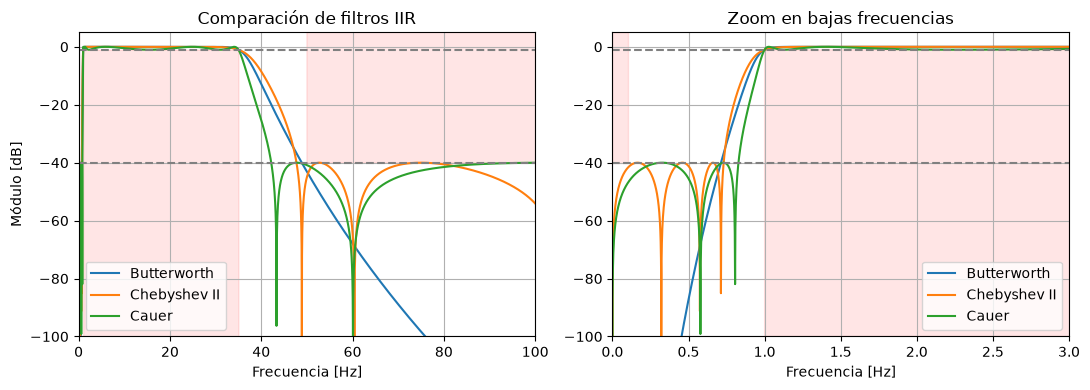

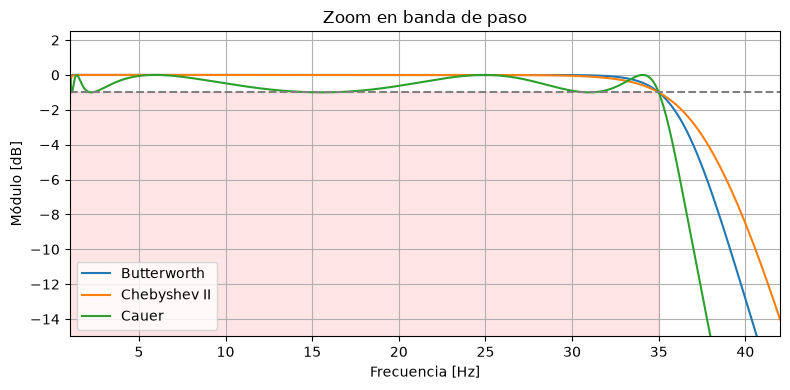

In [8]:
#%% Diseño IIR - Butterworth
wp = [wp1, wp2]  # Límites de la banda de paso 
ws = [ws1, ws2]  # Límites de las bandas de rechazo 

sos_butt = signal.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='butter', fs=fs_ecg, output='sos')
#gpass: max atenuacion permitida en la BP (1dB)
#gstop:minima atenuacion requerida en las BR (40dB)
#output='sos' nos devuelve el filtro expresado en secciones de segundo orden. 
print('\nFILTRO BUTTERWORTH')
print('Secciones de segundo orden:', len(sos_butt))
print('Orden del filtro digital:', 2*len(sos_butt))

#ahora verificamos la rta en frec. calculamos su rta H(e^jomega) y graficamos su modulo en dB
f = np.unique(np.r_[np.linspace(0, 3, 3001), np.linspace(3, 100, 5000), np.linspace(100, 500, 3000), ws1, wp1, wp2, ws2])
W = 2*np.pi*f/fs_ecg
_, H_butt = signal.freqz_sos(sos_butt, worN=W)
mod_butt = 20*np.log10(np.maximum(np.abs(H_butt), 1e-12))

#verificacion numerica de la plantilla:
paso = (f>=wp1)&(f<=wp2)
rechazo_inf = f<=ws1
rechazo_sup = f>=ws2

print('Mínimo en banda de paso:', round(np.min(mod_butt[paso]), 2), 'dB')
print('Máximo en rechazo inferior:', round(np.max(mod_butt[rechazo_inf]), 2), 'dB')
print('Máximo en rechazo superior:', round(np.max(mod_butt[rechazo_sup]), 2), 'dB')


#%% Diseño IIR - Cauer
sos_cauer = signal.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='ellip', fs=fs_ecg, output='sos')

print('\nFILTRO CAUER')
print('Secciones de segundo orden:', len(sos_cauer))
print('Orden del filtro digital:', 2*len(sos_cauer))

# Respuesta en frecuencia
_, H_cauer = signal.freqz_sos(sos_cauer, worN=W)
mod_cauer = 20*np.log10(np.maximum(np.abs(H_cauer), 1e-12))

# Verificación de la plantilla
print('Mínimo en banda de paso:', round(np.min(mod_cauer[paso]), 2), 'dB')
print('Máximo en rechazo inferior:', round(np.max(mod_cauer[rechazo_inf]), 2), 'dB')
print('Máximo en rechazo superior:', round(np.max(mod_cauer[rechazo_sup]), 2), 'dB')


#%% Diseño IIR - Chebyshev II
sos_cheby2 = signal.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='cheby2', fs=fs_ecg, output='sos')

print('\nFILTRO CHEBYSHEV II')
print('Secciones de segundo orden:', len(sos_cheby2))
print('Orden del filtro digital:', 2*len(sos_cheby2))

# Respuesta en frecuencia
_, H_cheby2 = signal.freqz_sos(sos_cheby2, worN=W)
mod_cheby2 = 20*np.log10(np.maximum(np.abs(H_cheby2), 1e-12))

# Verificación de la plantilla
print('Mínimo en banda de paso:', round(np.min(mod_cheby2[paso]), 2), 'dB')
print('Máximo en rechazo inferior:', round(np.max(mod_cheby2[rechazo_inf]), 2), 'dB')
print('Máximo en rechazo superior:', round(np.max(mod_cheby2[rechazo_sup]), 2), 'dB')


#%% Comparación IIR - Butterworth, Chebyshev II y Cauer
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, limites in zip(ax, [(0, 100), (0, 3)]):
    a.plot(f, mod_butt, label='Butterworth')
    a.plot(f, mod_cheby2, label='Chebyshev II')
    a.plot(f, mod_cauer, label='Cauer')
    a.fill_between(f, -100, -ripple, where=(f>=wp1)&(f<=wp2), color='red', alpha=0.1)
    a.fill_between(f, -atenuacion, 5, where=(f<=ws1)|(f>=ws2), color='red', alpha=0.1)
    a.axhline(-ripple, color='gray', ls='--')
    a.axhline(-atenuacion, color='gray', ls='--')
    a.set_xlim(limites)
    a.set_ylim(-100, 5)
    a.set_xlabel('Frecuencia [Hz]')
    a.grid(True)
    a.legend()
ax[0].set_ylabel('Módulo [dB]')
ax[0].set_title('Comparación de filtros IIR')
ax[1].set_title('Zoom en bajas frecuencias')
plt.tight_layout()
plt.show()

#%% Zoom en banda de paso
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(f, mod_butt, label='Butterworth')
ax.plot(f, mod_cheby2, label='Chebyshev II')
ax.plot(f, mod_cauer, label='Cauer')
ax.fill_between(f, -100, -ripple, where=(f>=wp1)&(f<=wp2), color='red', alpha=0.1)
ax.axhline(-ripple, color='gray', ls='--')
ax.set_xlim(1, 42)
ax.set_ylim(-15, 2.5)
ax.set_title('Zoom en banda de paso')
ax.set_xlabel('Frecuencia [Hz]')
ax.set_ylabel('Módulo [dB]')
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

Los tres filtros IIR diseñados cumplen con las especificaciones de la plantilla, presentando una atenuación máxima de 1 dB en la banda de paso y una atenuación mínima de 40 dB en las bandas de rechazo.

El filtro **Butterworth** requirió un orden digital de 30, mientras que **Chebyshev tipo II** necesitó un orden de 14 y **Cauer** uno de 10. Esto demuestra que Butterworth requiere un orden considerablemente mayor para alcanzar la misma selectividad, debido a su respuesta de máxima planicidad y sus transiciones más graduales. Este mayor orden implica también un mayor costo computacional, al necesitar más operaciones para implementar el filtrado.

Por su parte, **Chebyshev tipo II** presenta un comportamiento intermedio, manteniendo una banda de paso sin rizado y mejorando la selectividad respecto de Butterworth mediante oscilaciones en las bandas de rechazo.

El filtro **Cauer** logra las transiciones más abruptas con el menor orden, gracias a la presencia de rizado tanto en la banda de paso como en las de rechazo y a sus ceros de transmisión, que producen anulaciones de la respuesta en determinadas frecuencias.

En conclusión, Cauer resulta el más eficiente en términos de orden y selectividad. Sin embargo, esto no significa necesariamente que sea el más adecuado para nuestro ECG, ya que también será necesario evaluar las diferencias de fase y retardo de grupo, así como su efecto sobre la morfología temporal de los latidos.

#### Diseño y comparación de los filtros FIR

Luego, se procedió al diseño de cuatro filtros FIR pasabanda, utilizando diferentes métodos de aproximación.

En primer lugar, se empleó el **método de ventanas**, mediante la función `signal.firwin2()`, utilizando Hamming y Blackman. Se seleccionaron estas ventanas para comparar el compromiso entre el ancho del lóbulo principal y la atenuación de los lóbulos secundarios. Hamming presenta un lóbulo principal relativamente angosto, mientras que Blackman logra una mayor atenuación de los lóbulos secundarios, pero con un lóbulo principal más ancho para una misma cantidad de coeficientes. Por lo tanto, esta última generalmente requiere más coeficientes para conseguir transiciones igualmente estrechas.

Posteriormente, se diseñó un filtro mediante **mínimos cuadrados**, utilizando `signal.firls()`. A diferencia del método de ventanas, este procedimiento calcula los coeficientes minimizando el error cuadrático integrado entre la respuesta deseada y la obtenida. Además, permite asignar distintos pesos a las bandas de frecuencia según su importancia.

Finalmente, se diseñó un único filtro pasabanda utilizando el algoritmo de **Parks-McClellan** `signal.remez()`, el cual minimiza el máximo error ponderado distribuyendo las oscilaciones de manera controlada en las bandas de interés (*equiripple*). Como el diseño directo presentó dificultades numéricas con la plantilla original, se utilizó una **plantilla relajada** exclusivamente para este método: rechazo inferior hasta 0,5 Hz, paso entre 4 y 35 Hz y rechazo superior desde 40 Hz, con atenuación máxima de 3 dB en paso y mínima de 20 dB en rechazo. Así se obtuvo un filtro de 501 coeficientes (orden 500). Esta excepción debe distinguirse de los otros seis filtros, que se diseñaron para la plantilla original.

A continuación, se presenta el código correspondiente al diseño de los cuatro filtros FIR y la comparación de sus respuestas en frecuencia.



FIR Hamming
Orden: 3500
Mínimo en paso: -0.73 dB
Máximo rechazo inferior: -42.81 dB
Máximo rechazo superior: -98.46 dB
Retardo de grupo: 1.75 s

FIR Blackman
Orden: 5000
Mínimo en paso: -0.61 dB
Máximo rechazo inferior: -43.7 dB
Máximo rechazo superior: -149.02 dB
Retardo de grupo: 2.5 s

FILTRO FIR - MÍNIMOS CUADRADOS
Orden: 2500
Mínimo en paso: -0.4 dB
Máximo rechazo inferior: -43.56 dB
Máximo rechazo superior: -63.04 dB
Máximo en transición superior: -0.12 dB
Retardo de grupo: 1.25 s

FILTRO FIR - PARKS-MCCLELLAN
Orden: 500
Ganancia mínima en paso: -0.29 dB
Máximo rechazo inferior: -35.81 dB
Máximo rechazo superior: -35.81 dB
Retardo de grupo: 0.25 s


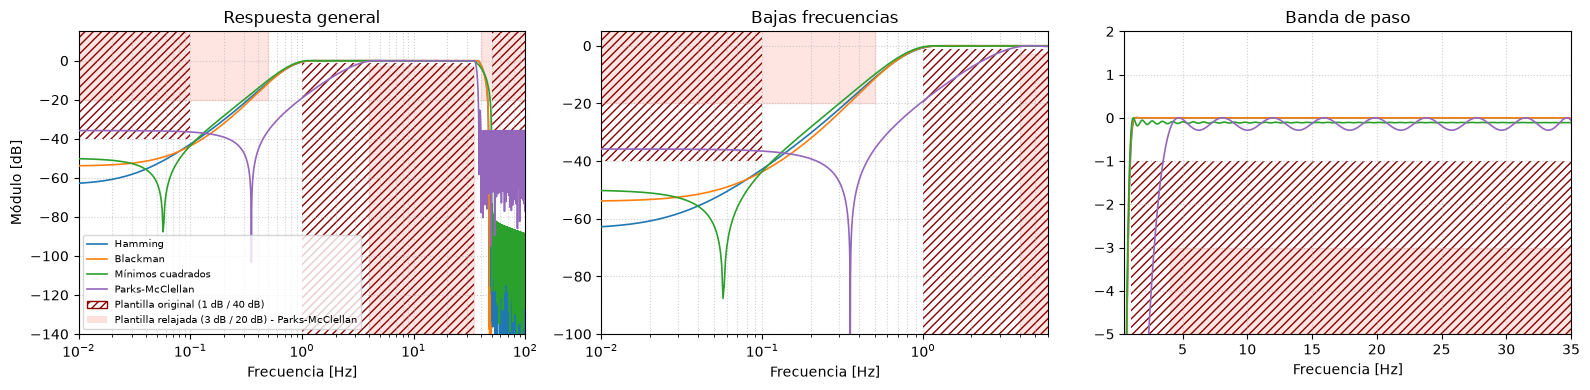

In [9]:
#%% Diseño FIR - Método de ventanas
# Definimos la respuesta deseada mediante puntos en frecuencia.
# Los límites se ajustan dentro de las bandas de transición para cumplir la plantilla.
#dejamos un margen respecto d elos limites obligatorios
freq_win = [0, 0.4, 0.9, 38, 47, nyq_frec]  # Frecuencias [Hz]
gain_win = [0, 0, 1, 1, 0, 0]  # Ganancia deseada en veces

# FIR con ventana Hamming
taps_win = 3501  # Cantidad de coeficientes
b_win = signal.firwin2(taps_win, freq_win, gain_win, window='hamming', fs=fs_ecg)

# FIR con ventana Blackman
taps_black = 5001
b_black = signal.firwin2(taps_black, freq_win, gain_win, window='blackman', fs=fs_ecg)

#Respuestas en frecuencia
_, H_win = signal.freqz(b_win, worN=W)
_, H_black = signal.freqz(b_black, worN=W)
mod_win = 20*np.log10(np.maximum(np.abs(H_win), 1e-12))
mod_black = 20*np.log10(np.maximum(np.abs(H_black), 1e-12))

# Verificación de la plantilla y demora
for nombre, taps, mod in [('Hamming', taps_win, mod_win), ('Blackman', taps_black, mod_black)]:
    print('\nFIR', nombre)
    print('Orden:', taps-1)
    print('Mínimo en paso:', round(np.min(mod[paso]), 2), 'dB')
    print('Máximo rechazo inferior:', round(np.max(mod[rechazo_inf]), 2), 'dB')
    print('Máximo rechazo superior:', round(np.max(mod[rechazo_sup]), 2), 'dB')
    print('Retardo de grupo:', (taps-1)/(2*fs_ecg), 's')


#%% Diseño FIR - Mínimos cuadrados
taps_firls = 2501  # Cantidad de coeficientes
# Incluimos las transiciones para evitar picos excesivos
freq_firls = [0, ws1, ws1, wp1, wp1, wp2, wp2, ws2, ws2, nyq_frec]
gain_firls = [0, 0, 0, 1, 1, 1, 1, 0, 0, 0]
pesos = [100, 0.01, 1, 0.01, 10]  # Rechazo inf., transición, paso, transición, rechazo sup.

# Calculamos los coeficientes minimizando el error cuadrático ponderado
b_firls = signal.firls(taps_firls, freq_firls, gain_firls, weight=pesos, fs=fs_ecg)

# Normalizamos para que el máximo de la banda de paso sea 0 dB
_, H_temp = signal.freqz(b_firls, worN=W)
b_firls = b_firls/np.max(np.abs(H_temp[paso]))

# Respuesta en frecuencia
_, H_firls = signal.freqz(b_firls, worN=W)
mod_firls = 20*np.log10(np.maximum(np.abs(H_firls), 1e-12))

# Verificación de la plantilla
transicion_sup = (f>wp2)&(f<ws2)
print('\nFILTRO FIR - MÍNIMOS CUADRADOS')
print('Orden:', taps_firls-1)
print('Mínimo en paso:', round(np.min(mod_firls[paso]), 2), 'dB')
print('Máximo rechazo inferior:', round(np.max(mod_firls[rechazo_inf]), 2), 'dB')
print('Máximo rechazo superior:', round(np.max(mod_firls[rechazo_sup]), 2), 'dB')
print('Máximo en transición superior:', round(np.max(mod_firls[transicion_sup]), 2), 'dB')
print('Retardo de grupo:', (taps_firls-1)/(2*fs_ecg), 's')

#%% Diseño FIR - Parks-McClellan (Remez)
numtaps = 501 
ripple_relajado = 3         
atenuacion_relajada = 20    

ws1_rel = 0.5  
wp1_rel = 4.0  
wp2_rel = 35
ws2_rel = 40

bandas = [0, ws1_rel, wp1_rel, wp2_rel, ws2_rel, fs_ecg/2]
deseado = [0, 1, 0]
pesos = [1, 1, 1] 

b_remez_directo = signal.remez(
    numtaps, bandas, deseado, weight=pesos, fs=fs_ecg, 
    maxiter=500, grid_density=256
)
f_prueba = np.unique(np.r_[0, np.logspace(-3, np.log10(fs_ecg/2), 20000), ws1_rel, wp1_rel, wp2_rel, ws2_rel])

_, H_temp = signal.freqz(b_remez_directo, worN=f_prueba, fs=fs_ecg)
paso_temp = (f_prueba >= wp1_rel) & (f_prueba <= wp2_rel)
b_remez_directo = b_remez_directo / np.max(np.abs(H_temp[paso_temp]))

_, H_remez = signal.freqz(b_remez_directo, worN=f_prueba, fs=fs_ecg)
mod_remez = 20*np.log10(np.maximum(np.abs(H_remez), 1e-15))

paso_rel = (f_prueba>=wp1_rel)&(f_prueba<=wp2_rel)
rechazo_inf_rel = f_prueba<=ws1_rel
rechazo_sup_rel = f_prueba>=ws2_rel

print('\nFILTRO FIR - PARKS-MCCLELLAN')
print('Orden:', len(b_remez_directo)-1)
print('Ganancia mínima en paso:', round(np.min(mod_remez[paso_rel]), 2), 'dB')
print('Máximo rechazo inferior:', round(np.max(mod_remez[rechazo_inf_rel]), 2), 'dB')
print('Máximo rechazo superior:', round(np.max(mod_remez[rechazo_sup_rel]), 2), 'dB')
print('Retardo de grupo:', (len(b_remez_directo)-1)/(2*fs_ecg), 's')


#%% Comparación de los cuatro filtros FIR con ambas plantillas
from matplotlib.patches import Patch

filtros_fir = [
    ('Hamming', f, mod_win),
    ('Blackman', f, mod_black),
    ('Mínimos cuadrados', f, mod_firls),
    ('Parks-McClellan', f_prueba, mod_remez)
]

# Plantilla relajada: sombreado rojo claro (solo Parks-McClellan)
# Plantilla original: rayado diagonal rojo (restantes filtros)

def dibujar_plantillas_comparacion(a, ylim):
    ymin, ymax = ylim

    # PLANTILLA RELAJADA - sombreado rojo claro
    a.fill_between([0.001, ws1_rel], -atenuacion_relajada, ymax,
                   color='salmon', alpha=0.20, zorder=0)
    a.fill_between([wp1_rel, wp2_rel], ymin, -ripple_relajado,
                   color='salmon', alpha=0.20, zorder=0)
    a.fill_between([ws2_rel, nyq_frec], -atenuacion_relajada, ymax,
                   color='salmon', alpha=0.20, zorder=0)

    # PLANTILLA ORIGINAL - rayado diagonal rojo
    estilo_original = dict(facecolor='none', edgecolor='darkred',
                           hatch='////', linewidth=0, zorder=1)

    a.fill_between([0.001, ws1], -atenuacion, ymax, **estilo_original)
    a.fill_between([wp1, wp2], ymin, -ripple, **estilo_original)
    a.fill_between([ws2, nyq_frec], -atenuacion, ymax, **estilo_original)

# Etiquetas de las plantillas
leyenda_plantillas = [
    Patch(facecolor='none', edgecolor='darkred', hatch='////',
          label='Plantilla original (1 dB / 40 dB)'),
    Patch(facecolor='salmon', alpha=0.25,
          label='Plantilla relajada (3 dB / 20 dB) - Parks-McClellan')
]

# Gráficos comparativos
graficos = [
    ('Respuesta general', (0.01, 100), (-140, 15)),
    ('Bajas frecuencias', (0.01, 6), (-100, 5)),
    ('Banda de paso', (0.5, 35), (-5, 2))
]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

for a, (titulo, xlim, ylim) in zip(ax, graficos):
    dibujar_plantillas_comparacion(a, ylim)

    for nombre, vector_f, mod in filtros_fir:
        a.plot(vector_f, mod, label=nombre, linewidth=1.2,
               color='tab:purple' if nombre=='Parks-McClellan' else None,
               zorder=3)

    if titulo != 'Banda de paso':
        a.set_xscale('log')

    a.set_xlim(xlim)
    a.set_ylim(ylim)
    a.set_title(titulo)
    a.set_xlabel('Frecuencia [Hz]')
    a.grid(True, which='both', ls=':', alpha=0.6)

ax[0].set_ylabel('Módulo [dB]')

# Leyenda conjunta de filtros y plantillas
curvas, etiquetas = ax[0].get_legend_handles_labels()
ax[0].legend(curvas + leyenda_plantillas,
             etiquetas + [h.get_label() for h in leyenda_plantillas],
             fontsize=7, loc='lower left')

plt.tight_layout()
plt.show()



Los filtros FIR Hamming, Blackman y mínimos cuadrados cumplieron con la plantilla original; Parks-McClellan cumplió con una plantilla relajada definida únicamente para ese diseño. Por ello, sus órdenes no son directamente comparables bajo las mismas exigencias. Los tres FIR de la plantilla original requirieron órdenes considerablemente mayores que los IIR. Esto se debe principalmente a la estrecha banda de transición inferior, comprendida entre 0,1 y 1 Hz (ancho de 0,9 Hz), frente a la transición superior de 35 a 50 Hz (ancho de 15 Hz). Como vimos en clase, conseguir transiciones muy estrechas mediante filtros FIR requiere una respuesta al impulso más larga y, por lo tanto, una mayor cantidad de coeficientes.

Los filtros diseñados mediante **ventanas Hamming y Blackman** necesitaron órdenes de 3500 y 5000, respectivamente. Ambos presentaron respuestas prácticamente planas en la banda de paso, aunque Blackman alcanzó una mayor atenuación en el rechazo superior. Sin embargo, necesitó más coeficientes, lo que implica un mayor costo computacional y demora.

Por su parte, el filtro de **cuadrados mínimos** permitió reducir el orden a 2500. Para su diseño se asignaron pesos de 100 al rechazo inferior, 1 a la banda de paso y 10 al rechazo superior, priorizando especialmente el cumplimiento de la especificación en bajas frecuencias. Además, se incorporaron las bandas de transición con pesos reducidos de 0,01 para evitar los picos excesivos de ganancia observados inicialmente.

Finalmente, el filtro de **Parks-McClellan** logró el menor orden de todos (500). Debido a problemas de convergencia al intentar un diseño pasabanda estricto, se decidió relajar la plantilla original. Esta estrategia permitió estabilizar el algoritmo y cumplir los requerimientos en una sola etapa, exhibiendo su clásico comportamiento equiripple. El diseño obtenido cumple esa plantilla relajada, pero **no la original**. 

En conclusión, los cuatro métodos permitieron satisfacer la plantilla, aunque presentaron diferencias en sus respuestas en frecuencia, órdenes y costos computacionales. Entre los diseños obtenidos, Parks-McClellan requirió la menor cantidad de coeficientes bajo la plantilla relajada, mientras que Blackman presentó el mayor orden y, por lo tanto, la mayor demora.

#### Comparación de las respuestas en frecuencia de los filtros FIR e IIR

Una vez diseñados y analizados los filtros FIR e IIR por separado, se realizó una comparación conjunta de sus respuestas en frecuencia, fase y retardo de grupo, con el objetivo de evaluar las principales diferencias entre ambas familias.

En primer lugar, se compararon las respuestas en módulo, analizando el comportamiento de los filtros en las bandas de paso, transición y rechazo. Posteriormente, se estudiaron las respuestas de fase y retardo de grupo, considerando su importancia en la conservación de la morfología temporal del ECG.

A continuación, se presenta el código correspondiente a ambas comparaciones y sus respectivos gráficos.

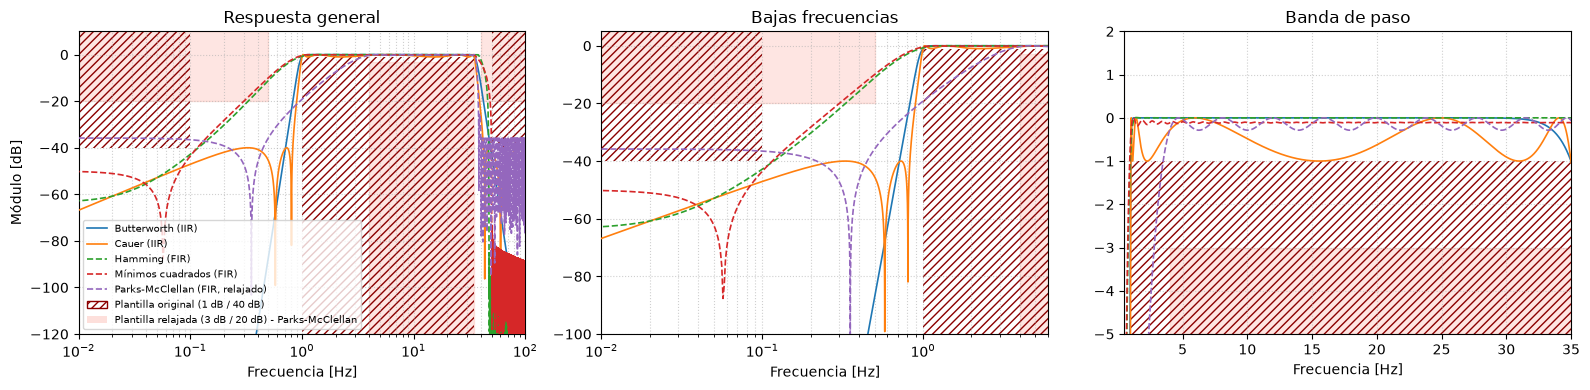

Butterworth - Retardo mínimo: 51.11 ms - Máximo: 136.99 ms
Chebyshev II - Retardo mínimo: 16.0 ms - Máximo: 42.44 ms
Cauer - Retardo mínimo: 15.42 ms - Máximo: 108.58 ms
Hamming - Retardo: 1750.0 ms
Blackman - Retardo: 2500.0 ms
Mínimos cuadrados - Retardo: 1250.0 ms
Parks-McClellan - Retardo: 250.0 ms


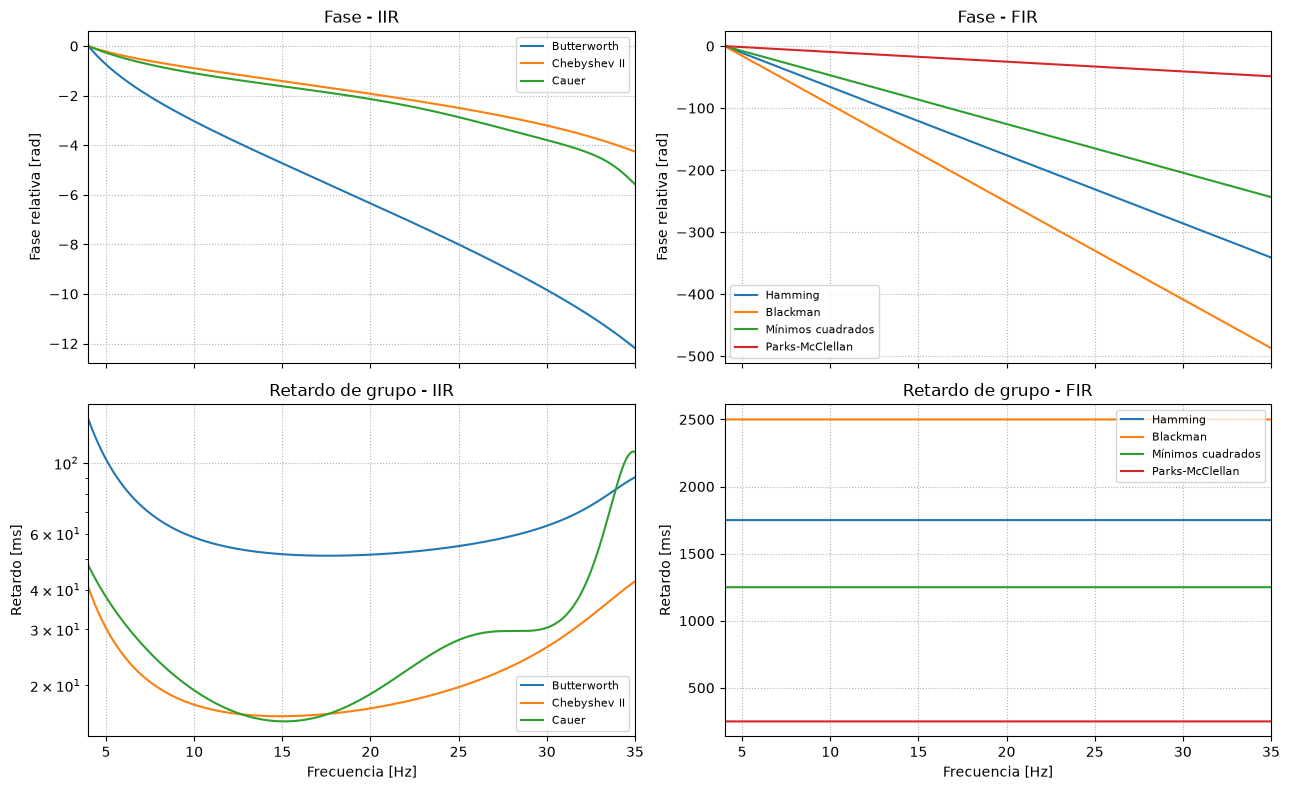

In [10]:
#%% Comparación FIR vs IIR - Respuesta en frecuencia
from matplotlib.patches import Patch

# Si ya definiste esto arriba, no hace falta repetirlo.
# Lo dejo igual para que esta celda funcione sola.
def dibujar_plantillas_comparacion(a, ylim):
    ymin, ymax = ylim

    # Plantilla relajada (solo Parks-McClellan): sombreado rojo claro
    a.fill_between([0.001, ws1_rel], -atenuacion_relajada, ymax,
                   color='salmon', alpha=0.20, zorder=0)
    a.fill_between([wp1_rel, wp2_rel], ymin, -ripple_relajado,
                   color='salmon', alpha=0.20, zorder=0)
    a.fill_between([ws2_rel, nyq_frec], -atenuacion_relajada, ymax,
                   color='salmon', alpha=0.20, zorder=0)

    # Plantilla original: rayado diagonal rojo
    estilo_original = dict(facecolor='none', edgecolor='darkred',
                           hatch='////', linewidth=0, zorder=1)

    a.fill_between([0.001, ws1], -atenuacion, ymax, **estilo_original)
    a.fill_between([wp1, wp2], ymin, -ripple, **estilo_original)
    a.fill_between([ws2, nyq_frec], -atenuacion, ymax, **estilo_original)

leyenda_plantillas = [
    Patch(facecolor='none', edgecolor='darkred', hatch='////',
          label='Plantilla original (1 dB / 40 dB)'),
    Patch(facecolor='salmon', alpha=0.25,
          label='Plantilla relajada (3 dB / 20 dB) - Parks-McClellan')
]

# La comparación incluye cinco curvas por claridad; los siete filtros ya fueron diseñados.
filtros_comp = [
    ('Butterworth (IIR)', f, mod_butt),
    ('Cauer (IIR)', f, mod_cauer),
    ('Hamming (FIR)', f, mod_win),
    ('Mínimos cuadrados (FIR)', f, mod_firls),
    ('Parks-McClellan (FIR, relajado)', f_prueba, mod_remez)
]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
graficos = [
    ('Respuesta general', (0.01, 100), (-120, 10)),
    ('Bajas frecuencias', (0.01, 6), (-100, 5)),
    ('Banda de paso', (0.5, 35), (-5, 2))
]

for a, (titulo, xlim, ylim) in zip(ax, graficos):
    dibujar_plantillas_comparacion(a, ylim)

    for nombre, vector_f, modulo in filtros_comp:
        estilo = '--' if 'FIR' in nombre else '-'
        color = 'tab:purple' if 'Parks-McClellan' in nombre else None
        a.plot(vector_f, modulo, ls=estilo, label=nombre,
               linewidth=1.2, color=color, zorder=3)

    if titulo != 'Banda de paso':
        a.set_xscale('log')

    a.set_xlim(xlim)
    a.set_ylim(ylim)
    a.set_title(titulo)
    a.set_xlabel('Frecuencia [Hz]')
    a.grid(True, which='both', ls=':', alpha=0.6)

ax[0].set_ylabel('Módulo [dB]')

curvas, etiquetas = ax[0].get_legend_handles_labels()
ax[0].legend(curvas + leyenda_plantillas,
             etiquetas + [h.get_label() for h in leyenda_plantillas],
             fontsize=7, loc='lower left')

plt.tight_layout()
plt.show()


#%% Comparación FIR vs IIR - Fase y retardo de grupo
# Analizamos 4-35 Hz: banda de paso compartida por los siete diseños
f_paso = np.linspace(wp1_rel, wp2_rel, 6000)
W_paso = 2*np.pi*f_paso/fs_ecg  # Frecuencia digital [rad/muestra]

filtros_iir = [
    ('Butterworth', sos_butt),
    ('Chebyshev II', sos_cheby2),
    ('Cauer', sos_cauer)
]

filtros_fir = [
    ('Hamming', b_win),
    ('Blackman', b_black),
    ('Mínimos cuadrados', b_firls),
    ('Parks-McClellan', b_remez_directo)
]

fig, ax = plt.subplots(2, 2, figsize=(13, 8), sharex='col')

# Filtros IIR: fase no lineal y retardo variable
for nombre, sos in filtros_iir:
    _, H = signal.freqz_sos(sos, worN=W_paso)
    fase = np.unwrap(np.angle(H))
    demora = -np.gradient(fase, W_paso)*1000/fs_ecg  # Retardo [ms]

    ax[0,0].plot(f_paso, fase-fase[0], label=nombre)
    ax[1,0].plot(f_paso, demora, label=nombre)

    print(nombre, '- Retardo mínimo:', round(np.min(demora), 2),
          'ms - Máximo:', round(np.max(demora), 2), 'ms')

# Filtros FIR: fase lineal y retardo constante
for nombre, b in filtros_fir:
    _, H = signal.freqz(b, worN=W_paso)
    fase = np.unwrap(np.angle(H))
    demora = (len(b)-1)/(2*fs_ecg)*1000  # Retardo [ms]

    ax[0,1].plot(f_paso, fase-fase[0], label=nombre)
    ax[1,1].plot(f_paso, np.full_like(f_paso, demora), label=nombre)

    print(nombre, '- Retardo:', round(demora, 2), 'ms')

# Formato de los gráficos
for a in ax.flat:
    a.grid(True, ls=':')
    a.legend(fontsize=8)
    a.set_xlim(wp1_rel, wp2_rel)

ax[0,0].set_title('Fase - IIR')
ax[0,1].set_title('Fase - FIR')
ax[1,0].set_title('Retardo de grupo - IIR')
ax[1,1].set_title('Retardo de grupo - FIR')

ax[0,0].set_ylabel('Fase relativa [rad]')
ax[0,1].set_ylabel('Fase relativa [rad]')
ax[1,0].set_ylabel('Retardo [ms]')
ax[1,1].set_ylabel('Retardo [ms]')

ax[1,0].set_xlabel('Frecuencia [Hz]')
ax[1,1].set_xlabel('Frecuencia [Hz]')
ax[1,0].set_yscale('log')

plt.tight_layout()
plt.show()

Al comparar las respuestas en módulo, se observó que los filtros IIR y los FIR Hamming, Blackman y mínimos cuadrados cumplen la plantilla original, mientras que Parks-McClellan cumple únicamente la plantilla relajada. Sin embargo, se observa que presentan diferencias en su selectividad y comportamiento frecuencial. Butterworth y los filtros por ventanas muestran respuestas prácticamente planas en la banda de paso, mientras que Cauer y Parks-McClellan presentan oscilaciones más pronunciadas. Además, Cauer se destaca por sus transiciones abruptas, mientras que los FIR alcanzan atenuaciones elevadas en las bandas de rechazo.

Por otro lado, el análisis de fase y retardo de grupo permitió identificar una diferencia fundamental entre ambas familias. Los **filtros IIR presentan fase no lineal**, representada por curvas cuya pendiente varía con la frecuencia. Como el retardo de grupo depende de la pendiente negativa de la fase, esto implica que las distintas componentes frecuenciales experimentan demoras diferentes, pudiendo modificar la morfología de los latidos. En particular, Butterworth presentó variaciones importantes de retardo, especialmente en las frecuencias más bajas.

En cambio, los **filtros FIR diseñados presentan fase lineal**, representada por rectas descendentes de pendiente constante. Por lo tanto, su retardo de grupo es constante, permitiendo que todas las componentes frecuenciales experimenten la misma demora y evitando deformaciones asociadas a diferencias de fase. Sin embargo, sus elevados órdenes introducen retardos considerables, comprendidos entre 1,125 y 2,5 segundos.

En conclusión, los **IIR presentan una ventaja en términos de orden y costo computacional**, mientras que los **FIR permiten conservar mejor las relaciones temporales entre las componentes de la señal**, aunque a costa de una mayor demora. Por lo tanto, la selección del filtro más adecuado no depende únicamente del cumplimiento de la plantilla, sino también de su comportamiento temporal y de los requisitos de la aplicación.

### d) Aplicación de los filtros al ECG

Una vez diseñados y verificados los filtros FIR e IIR, se procedió a aplicarlos sobre el registro de ECG para evaluar su capacidad de reducir las interferencias y conservar la morfología de los latidos.

En primer lugar, se realizó un **filtrado causal de una sola pasada**. Los filtros IIR se aplicaron mediante `signal.sosfilt()`, mientras que los FIR se implementaron mediante convolución. En estos últimos se compensó la demora constante para alinear temporalmente las señales y facilitar su comparación con el ECG original. Esta compensación se realizó únicamente sobre los resultados obtenidos, sin eliminar la demora propia del filtrado causal.


Se analizaron inicialmente las regiones comprendidas entre las muestras **4000–5500 y 10000–11000**, indicadas en la consigna como zonas con interferencias.

A continuación, se presenta el código correspondiente a la aplicación de los filtros y la comparación de los resultados obtenidos.

Cantidad de muestras: 1129116
Duración del registro: 18.8186 min


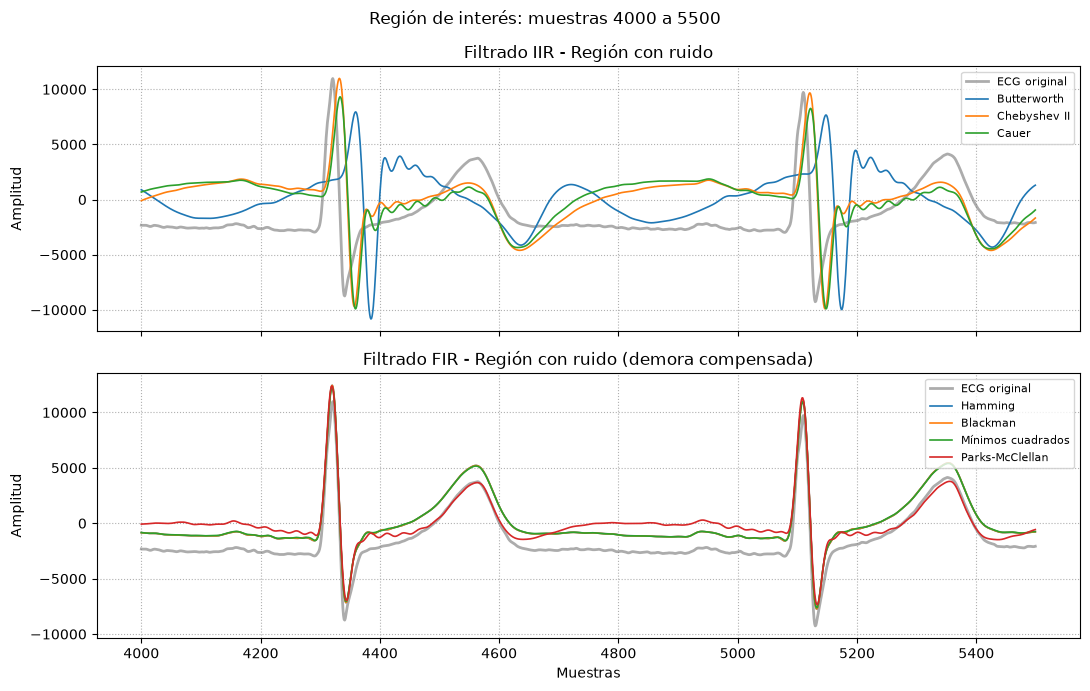

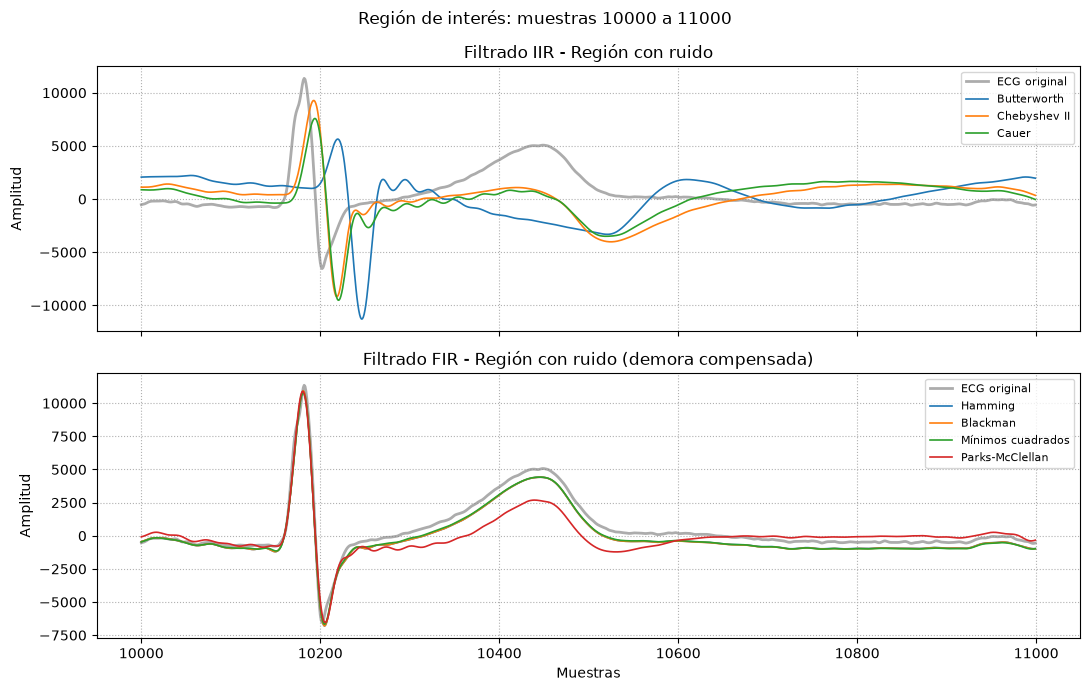

In [11]:
#%% Carga del ECG
datos = sio.loadmat('ECG_TP4.mat')
ecg_one_lead = datos['ecg_lead'].flatten().astype(float)
cant_muestras = len(ecg_one_lead)

print('Cantidad de muestras:', cant_muestras)
print('Duración del registro:', cant_muestras/fs_ecg/60, 'min')


#%% Aplicación de los filtros al ECG

# Filtros IIR: una pasada causal con condiciones iniciales
filtros_iir = [('Butterworth', sos_butt), ('Chebyshev II', sos_cheby2), ('Cauer', sos_cauer)]
ecg_iir = {}
for nombre, sos in filtros_iir:
    zi = signal.sosfilt_zi(sos)*ecg_one_lead[0]
    ecg_iir[nombre], _ = signal.sosfilt(sos, ecg_one_lead, zi=zi)

# Filtros FIR: convolución causal y compensación de demora
# CLAVE: Actualizamos a b_remez_directo
filtros_fir = [
    ('Hamming', b_win), 
    ('Blackman', b_black), 
    ('Mínimos cuadrados', b_firls), 
    ('Parks-McClellan', b_remez_directo) 
]
ecg_fir = {}
for nombre, b in filtros_fir:
    filtrada = signal.oaconvolve(ecg_one_lead, b, mode='full')[:cant_muestras]
    demora = (len(b)-1)//2  # Demora de grupo [muestras]
    alineada = np.full(cant_muestras, np.nan)
    alineada[:cant_muestras-demora] = filtrada[demora:]
    ecg_fir[nombre] = alineada


#%% Regiones de interés con ruido
regs_interes = ([4000, 5500], [10000, 11000])

for inicio, fin in regs_interes:
    zoom = np.arange(inicio, min(fin, cant_muestras))
    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

    # Comparación ECG original vs IIR
    ax[0].plot(zoom, ecg_one_lead[zoom], color='gray', alpha=0.65, linewidth=2, label='ECG original')
    for nombre, filtrada in ecg_iir.items():
        ax[0].plot(zoom, filtrada[zoom], label=nombre, linewidth=1.2)
    ax[0].set_title('Filtrado IIR - Región con ruido')
    ax[0].set_ylabel('Amplitud')

    # Comparación ECG original vs FIR
    ax[1].plot(zoom, ecg_one_lead[zoom], color='gray', alpha=0.65, linewidth=2, label='ECG original')
    for nombre, filtrada in ecg_fir.items():
        ax[1].plot(zoom, filtrada[zoom], label=nombre, linewidth=1.2)
    ax[1].set_title('Filtrado FIR - Región con ruido (demora compensada)')
    ax[1].set_xlabel('Muestras')
    ax[1].set_ylabel('Amplitud')

    for a in ax:
        a.grid(True, ls=":")
        a.legend(fontsize=8, loc='upper right')
    fig.suptitle(f'Región de interés: muestras {inicio} a {fin}')
    plt.tight_layout()
    plt.show()

Al aplicar los filtros a las regiones del ECG con interferencias, se observaron diferencias importantes en la conservación de la morfología de los latidos.

Los **filtros IIR**, especialmente Butterworth, presentaron desplazamientos temporales de los picos y modificaciones en la forma de los complejos QRS, incluyendo algunas oscilaciones adicionales. Chebyshev II y Cauer mostraron un comportamiento más favorable, aunque también introdujeron alteraciones. Estos resultados son coherentes con lo observado anteriormente: los IIR presentan fase no lineal y retardo de grupo variable.

En cambio, los **filtros FIR**, una vez compensada su demora constante, conservaron mejor la posición y morfología general de los latidos, reduciendo las fluctuaciones y los desplazamientos de la línea de base.

Sin embargo, debe considerarse que esta comparación no es completamente equivalente desde el punto de vista temporal, ya que los FIR fueron alineados con la señal original, mientras que los IIR conservaron sus retardos. Por este motivo, se decidió evaluar una alternativa de filtrado que permitiera eliminar el desfase introducido por los IIR.

Dado que se trabaja con un registro de ECG previamente adquirido y no se requiere procesamiento en tiempo real, se evaluó la aplicación de los filtros IIR mediante `signal.sosfiltfilt()`. Esta función realiza el filtrado en ambos sentidos, hacia adelante y hacia atrás, **permitiendo eliminar el desfase neto** y evitar las distorsiones temporales asociadas a la fase no lineal.

Sin embargo, este procedimiento modifica la respuesta en módulo, ya que las atenuaciones expresadas en decibeles se duplican. Por este motivo, se **rediseñaron los filtros IIR con especificaciones de 0,5 dB en la banda de paso y 20 dB en las bandas de rechazo por pasada**, de manera que la respuesta efectiva mantuviera los requisitos originales de 1 dB y 40 dB.

A continuación, se presenta el código correspondiente al rediseño y verificación de los filtros IIR de fase cero.

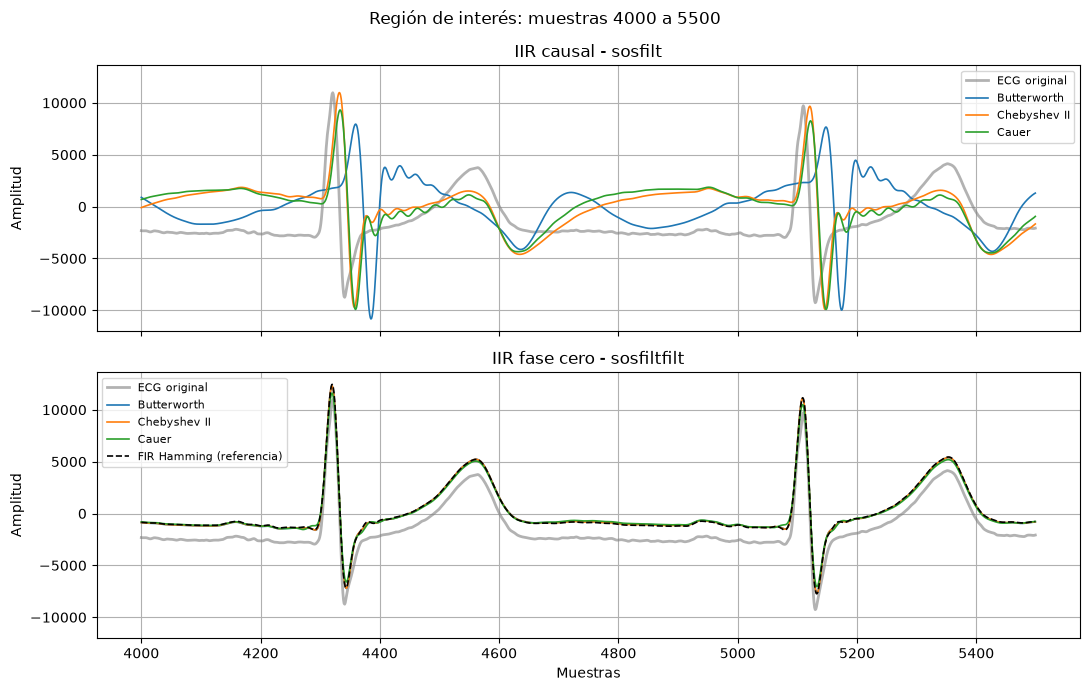

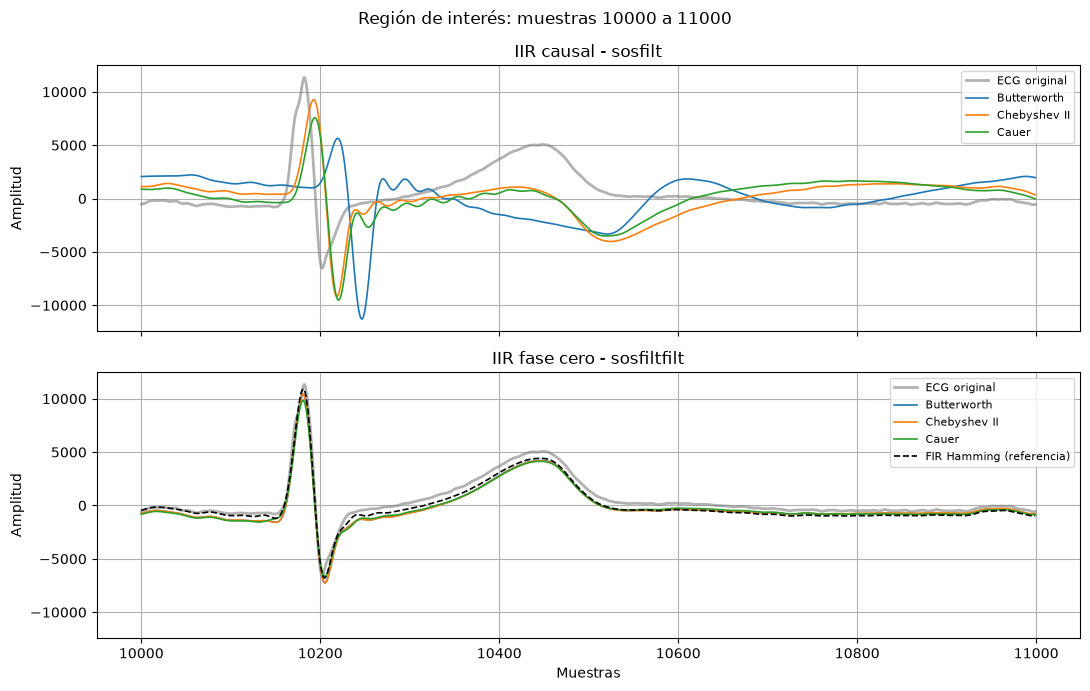


IIR FASE CERO - Butterworth
Mínimo en paso: -1.0 dB
Máximo en paso: 0.0 dB
Máximo rechazo inferior: -346.2 dB
Máximo rechazo superior: -40.57 dB

IIR FASE CERO - Chebyshev II
Mínimo en paso: -1.0 dB
Máximo en paso: 0.0 dB
Máximo rechazo inferior: -48.55 dB
Máximo rechazo superior: -40.0 dB

IIR FASE CERO - Cauer
Mínimo en paso: -1.0 dB
Máximo en paso: -0.0 dB
Máximo rechazo inferior: -58.34 dB
Máximo rechazo superior: -40.0 dB


In [12]:
#%% Filtrado IIR con fase cero - sosfiltfilt
# Como trabajamos fuera de tiempo real, usamos doble pasada para eliminar el desfase
# Diseñamos con la mitad de las atenuaciones, ya que sosfiltfilt duplica los dB

ecg_iir_cero = {}
sos_iir_cero = {}

for nombre, tipo in [('Butterworth', 'butter'), ('Chebyshev II', 'cheby2'), ('Cauer', 'ellip')]:
    sos = signal.iirdesign(wp, ws, gpass=ripple/2, gstop=atenuacion/2, ftype=tipo, fs=fs_ecg, output='sos')
    sos_iir_cero[nombre] = sos
    ecg_iir_cero[nombre] = signal.sosfiltfilt(sos, ecg_one_lead)
#%% Comparación IIR - Filtrado causal vs fase cero
regs_interes = ([4000, 5500], [10000, 11000])

for inicio, fin in regs_interes:
    zoom = np.arange(inicio, min(fin, cant_muestras))
    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, sharey=True)

    # IIR de una pasada: conservan el retardo y la distorsión de fase
    ax[0].plot(zoom, ecg_one_lead[zoom], color='gray', lw=2, alpha=0.6, label='ECG original')
    for nombre, filtrada in ecg_iir.items():
        ax[0].plot(zoom, filtrada[zoom], lw=1.2, label=nombre)
    ax[0].set_title('IIR causal - sosfilt')

    # IIR de doble pasada: fase cero
    ax[1].plot(zoom, ecg_one_lead[zoom], color='gray', lw=2, alpha=0.6, label='ECG original')
    for nombre, filtrada in ecg_iir_cero.items():
        ax[1].plot(zoom, filtrada[zoom], lw=1.2, label=nombre)
    ax[1].plot(zoom, ecg_fir['Hamming'][zoom], 'k--', lw=1.2, label='FIR Hamming (referencia)')
    ax[1].set_title('IIR fase cero - sosfiltfilt')
    ax[1].set_xlabel('Muestras')

    for a in ax:
        a.set_ylabel('Amplitud')
        a.grid(True)
        a.legend(fontsize=8)
    fig.suptitle(f'Región de interés: muestras {inicio} a {fin}')
    plt.tight_layout()
    plt.show()

#%% Verificación de los IIR con fase cero
f_ver = np.unique(np.r_[np.linspace(0, 3, 6001), np.linspace(3, 100, 10000), np.linspace(100, nyq_frec, 10000), ws1, wp1, wp2, ws2])
W_ver = 2*np.pi*f_ver/fs_ecg

for nombre, sos in sos_iir_cero.items():
    _, H = signal.freqz_sos(sos, worN=W_ver)
    modulo = 40*np.log10(np.maximum(np.abs(H), 1e-12))  # Módulo de doble pasada [dB]
    paso_ver = (f_ver>=wp1)&(f_ver<=wp2)
    rechazo_inf_ver = f_ver<=ws1
    rechazo_sup_ver = f_ver>=ws2
    print('\nIIR FASE CERO -', nombre)
    print('Mínimo en paso:', round(np.min(modulo[paso_ver]), 2), 'dB')
    print('Máximo en paso:', round(np.max(modulo[paso_ver]), 2), 'dB')
    print('Máximo rechazo inferior:', round(np.max(modulo[rechazo_inf_ver]), 2), 'dB')
    print('Máximo rechazo superior:', round(np.max(modulo[rechazo_sup_ver]), 2), 'dB')



La aplicación de los IIR con fase cero produjo una **mejora significativa en la conservación de la morfología del ECG**, especialmente en el caso de Butterworth. Los complejos QRS dejaron de presentar los desplazamientos temporales observados durante el filtrado causal y las señales obtenidas mostraron una mayor coincidencia con el registro original.

Los tres filtros IIR presentaron resultados similares entre sí y comparables con los obtenidos mediante los FIR con demora compensada, manteniendo la ubicación de los latidos y reduciendo las interferencias presentes.

Además, se verificó que los filtros rediseñados cumplen con las especificaciones originales de la plantilla después de la doble pasada.

Por lo tanto, el filtrado de fase cero resulta una alternativa conveniente para esta aplicación, ya que permite aprovechar el menor orden de los IIR sin introducir el desfase neto observado en el procesamiento causal.

#### Evaluación en las regiones sin ruido

Finalmente, se analizaron las regiones comprendidas entre **5–5,2 min, 12–12,4 min y 15–15,2 min**, indicadas en la consigna para evaluar la conservación de la señal original.

Para esta comparación se utilizaron los filtros FIR con demora compensada y los IIR con fase cero, buscando verificar que el filtrado no introdujera alteraciones significativas en la morfología de los latidos.

A continuación, se presenta el código correspondiente. 

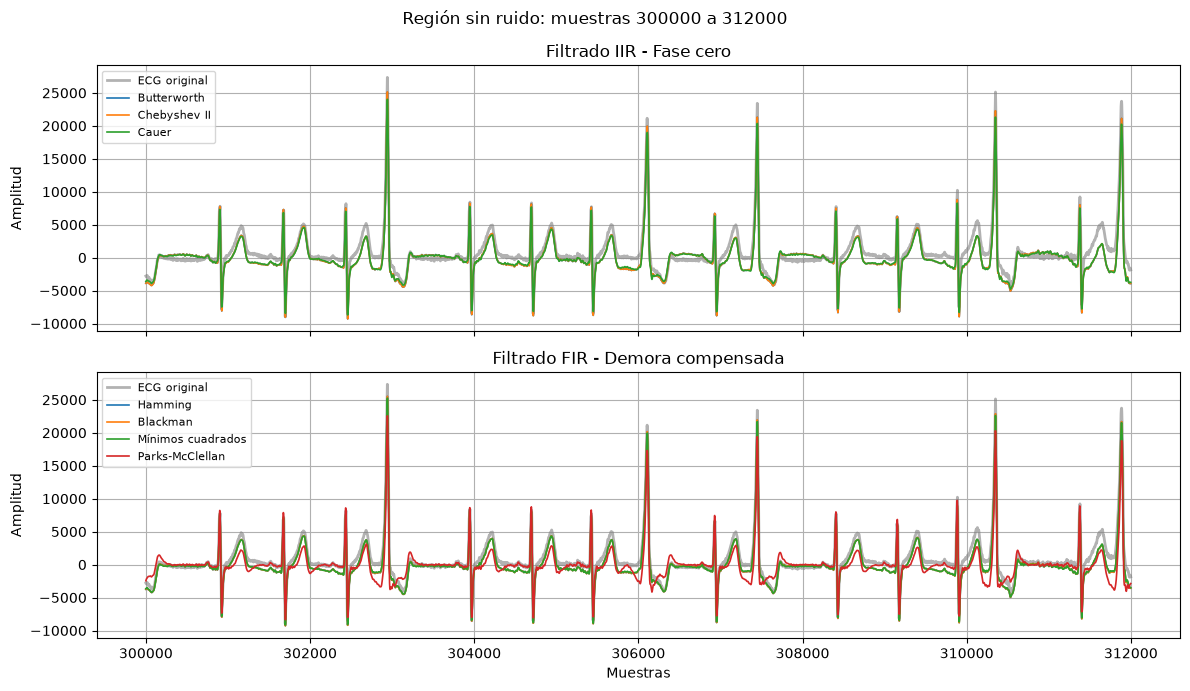

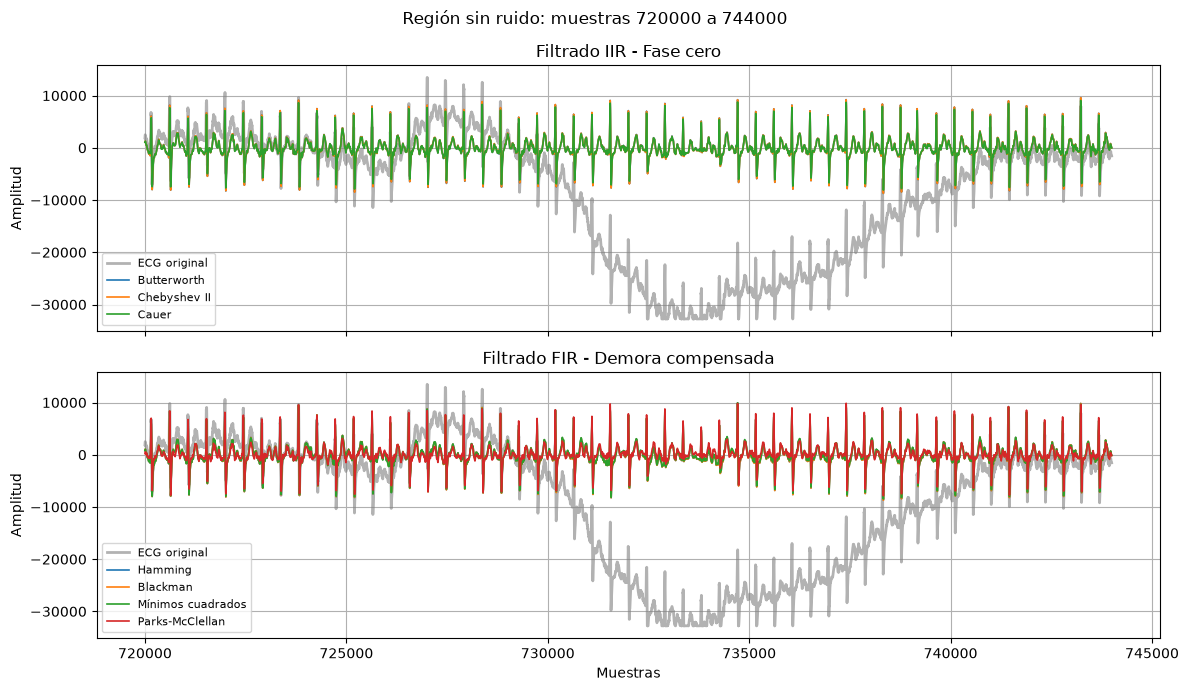

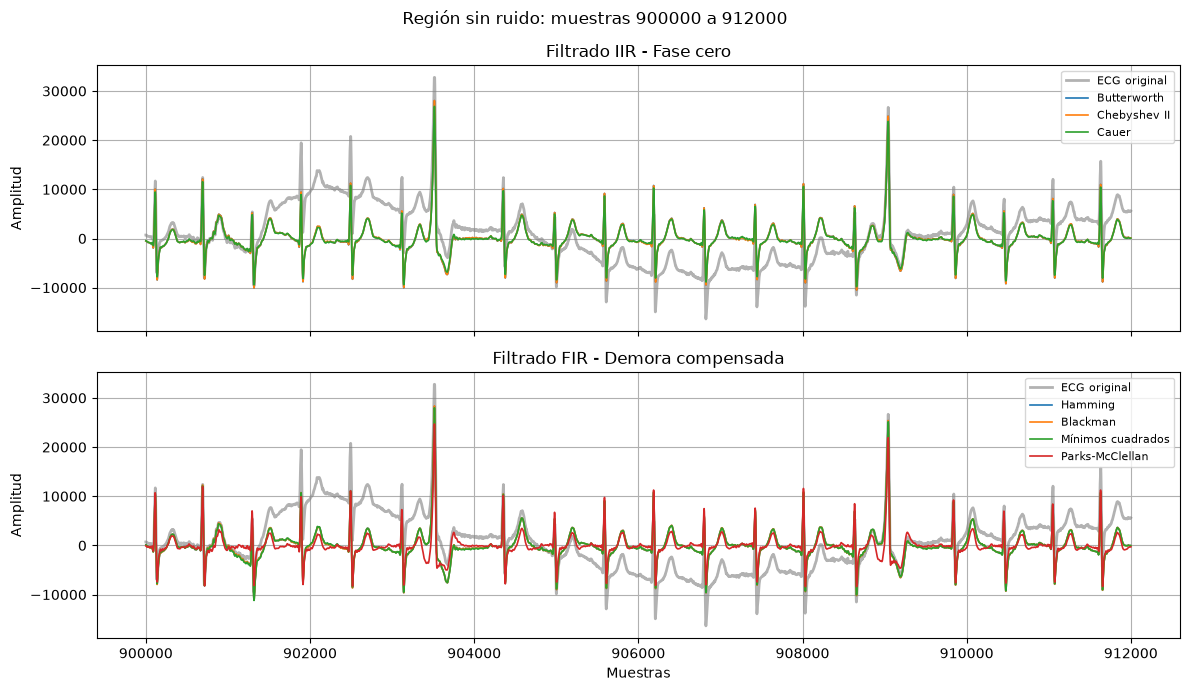

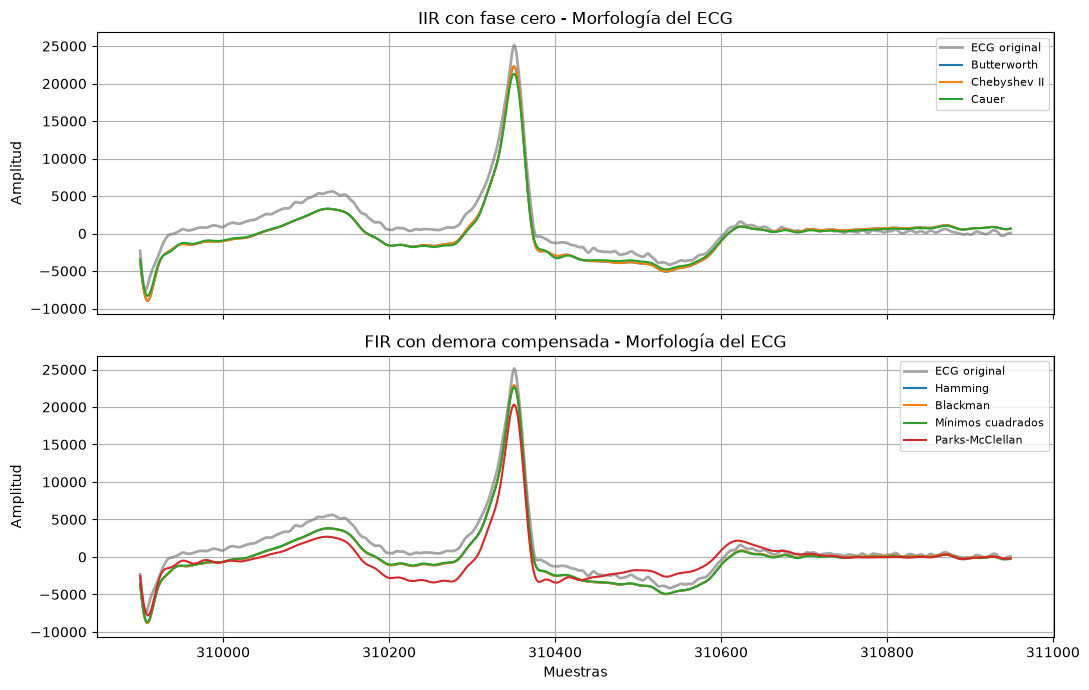

In [13]:
#%% Regiones de interés sin ruido
regs_limpias = (
    np.array([5, 5.2])*60*fs_ecg,
    np.array([12, 12.4])*60*fs_ecg,
    np.array([15, 15.2])*60*fs_ecg
)

for ii in regs_limpias:
    inicio = max(0, int(ii[0]))
    fin = min(cant_muestras, int(ii[1]))
    if inicio>=fin:
        print('Región fuera del registro:', ii)
        continue
    zoom = np.arange(inicio, fin)
    fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

    # ECG original vs IIR con fase cero
    ax[0].plot(zoom, ecg_one_lead[zoom], color='gray', lw=2, alpha=0.6, label='ECG original')
    for nombre, filtrada in ecg_iir_cero.items():
        ax[0].plot(zoom, filtrada[zoom], lw=1.2, label=nombre)
    ax[0].set_title('Filtrado IIR - Fase cero')

    # ECG original vs FIR con demora compensada
    ax[1].plot(zoom, ecg_one_lead[zoom], color='gray', lw=2, alpha=0.6, label='ECG original')
    for nombre, filtrada in ecg_fir.items():
        ax[1].plot(zoom, filtrada[zoom], lw=1.2, label=nombre)
    ax[1].set_title('Filtrado FIR - Demora compensada')
    ax[1].set_xlabel('Muestras')

    for a in ax:
        a.set_ylabel('Amplitud')
        a.grid(True)
        a.legend(fontsize=8)
    fig.suptitle(f'Región sin ruido: muestras {inicio} a {fin}')
    plt.tight_layout()
    plt.show()


#%% Zoom para analizar la morfología del ECG
inicio, fin = 309900, 310950
zoom = np.arange(inicio, fin)

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, sharey=True)

# IIR con fase cero
ax[0].plot(zoom, ecg_one_lead[zoom], color='gray', lw=2, alpha=0.7, label='ECG original')
for nombre, filtrada in ecg_iir_cero.items():
    ax[0].plot(zoom, filtrada[zoom], label=nombre)
ax[0].set_title('IIR con fase cero - Morfología del ECG')

# FIR con demora compensada
ax[1].plot(zoom, ecg_one_lead[zoom], color='gray', lw=2, alpha=0.7, label='ECG original')
for nombre, filtrada in ecg_fir.items():
    ax[1].plot(zoom, filtrada[zoom], label=nombre)
ax[1].set_title('FIR con demora compensada - Morfología del ECG')
ax[1].set_xlabel('Muestras')

for a in ax:
    a.set_ylabel('Amplitud')
    a.grid(True)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

Observamos que, tanto los filtros FIR como los IIR de fase cero conservaron, la posición y morfología de los complejos QRS, sin introducir desplazamientos temporales significativos.

Además, en las regiones de 12–12,4 min y 15–15,2 min se observaron importantes variaciones de la línea de base en el ECG original, que fueron considerablemente reducidas mediante el filtrado.

Al ampliar un latido, se comprobó que, si bien se conserva su forma general, existen modificaciones en las amplitudes de algunas ondas, especialmente en las componentes de variación más lenta. Por lo tanto, los filtros presentan un comportamiento satisfactorio, aunque no completamente inocuo sobre la señal original.

#### Comparación final de los filtros diseñados
Como síntesis del análisis realizado, se elaboró una tabla comparativa de los siete filtros, considerando sus órdenes, retardos de grupo y atenuaciones alcanzadas en las bandas de paso y rechazo.

Para los IIR se distinguen el orden del diseño causal inicial y el del rediseño utilizado con `sosfiltfilt`. Para los FIR se presenta el orden y retardo teórico de la aplicación causal. Las atenuaciones de Parks-McClellan se evalúan según su **plantilla relajada**, mientras que las de los otros seis filtros corresponden a la **plantilla original**.

In [15]:
#%% Tabla comparativa final - Usamos los filtros ya diseñados, sin rediseñarlos
import pandas as pd
from IPython.display import display

def medidas_tabla(frec, respuesta_db, fp_inf, fp_sup, fr_inf, fr_sup,
                  max_paso, min_rechazo):
    banda_paso = (frec>=fp_inf)&(frec<=fp_sup)
    banda_inf = frec<=fr_inf
    banda_sup = frec>=fr_sup
    minimo_paso = np.min(respuesta_db[banda_paso])
    maximo_paso = np.max(respuesta_db[banda_paso])
    rechazo_inferior = -np.max(respuesta_db[banda_inf])
    rechazo_superior = -np.max(respuesta_db[banda_sup])
    cumple = (minimo_paso >= -max_paso-0.01 and maximo_paso <= 0.01 and
              rechazo_inferior >= min_rechazo-0.01 and
              rechazo_superior >= min_rechazo-0.01)
    return round(maximo_paso-minimo_paso, 2), round(rechazo_inferior, 2), round(rechazo_superior, 2), cumple

filas = []
# IIR: orden inicial causal y orden del rediseño aplicado con sosfiltfilt.
for nombre, sos_causal in [('Butterworth', sos_butt), ('Chebyshev II', sos_cheby2), ('Cauer', sos_cauer)]:
    sos = sos_iir_cero[nombre]
    _, H = signal.freqz_sos(sos, worN=W_ver)
    mod = 40*np.log10(np.maximum(np.abs(H), 1e-12))  # respuesta efectiva de doble pasada
    variacion, rech_inf, rech_sup, cumple = medidas_tabla(
        f_ver, mod, wp1, wp2, ws1, ws2, ripple, atenuacion)
    filas.append([nombre + ' (IIR)', 'Original', 2*len(sos_causal), 2*len(sos),
                  '0 neto (doble pasada)', variacion, rech_inf, rech_sup,
                  'Sí' if cumple else 'No', 'Sí' if cumple else 'No'])

# FIR de una pasada con la plantilla original.
for nombre, b in [('Hamming', b_win), ('Blackman', b_black), ('Mínimos cuadrados', b_firls)]:
    _, H = signal.freqz(b, worN=W)
    mod = 20*np.log10(np.maximum(np.abs(H), 1e-12))
    variacion, rech_inf, rech_sup, cumple = medidas_tabla(
        f, mod, wp1, wp2, ws1, ws2, ripple, atenuacion)
    orden = len(b)-1
    filas.append([nombre + ' (FIR)', 'Original', orden, orden,
                  f'{orden/(2*fs_ecg)*1000:.0f} ms', variacion, rech_inf, rech_sup,
                  'Sí' if cumple else 'No', 'Sí' if cumple else 'No'])

# Parks-McClellan: sólo cambian sus propias especificaciones, no las de los otros filtros.
_, H = signal.freqz(b_remez_directo, worN=f_prueba, fs=fs_ecg)
mod = 20*np.log10(np.maximum(np.abs(H), 1e-15))
variacion, rech_inf, rech_sup, cumple_rel = medidas_tabla(
    f_prueba, mod, wp1_rel, wp2_rel, ws1_rel, ws2_rel,
    ripple_relajado, atenuacion_relajada)
_, H_orig = signal.freqz(b_remez_directo, worN=f, fs=fs_ecg)
mod_orig = 20*np.log10(np.maximum(np.abs(H_orig), 1e-15))
_, _, _, cumple_orig = medidas_tabla(
    f, mod_orig, wp1, wp2, ws1, ws2, ripple, atenuacion)
orden = len(b_remez_directo)-1
filas.append(['Parks-McClellan (FIR)', 'Relajada', orden, orden,
              f'{orden/(2*fs_ecg)*1000:.0f} ms', variacion, rech_inf, rech_sup,
              'Sí' if cumple_rel else 'No', 'Sí' if cumple_orig else 'No'])

columnas = ['Filtro', 'Plantilla', 'Orden causal/inicial', 'Orden aplicado',
            'Retardo de aplicación', 'Variación en paso [dB]',
            'Rechazo inferior [dB]', 'Rechazo superior [dB]',
            'Cumple propia plantilla', 'Cumple original']
df_comparacion = pd.DataFrame(filas, columns=columnas)
print('Tabla comparativa de los filtros diseñados:')
display(df_comparacion.style.hide(axis='index'))


Tabla comparativa de los filtros diseñados:


Filtro,Plantilla,Orden causal/inicial,Orden aplicado,Retardo de aplicación,Variación en paso [dB],Rechazo inferior [dB],Rechazo superior [dB],Cumple propia plantilla,Cumple original
Butterworth (IIR),Original,30,18,0 neto (doble pasada),1.000000,346.200000,40.570000,Sí,Sí
Chebyshev II (IIR),Original,14,10,0 neto (doble pasada),1.000000,48.550000,40.000000,Sí,Sí
Cauer (IIR),Original,10,6,0 neto (doble pasada),1.000000,58.340000,40.000000,Sí,Sí
Hamming (FIR),Original,3500,3500,1750 ms,0.730000,42.810000,98.460000,Sí,Sí
Blackman (FIR),Original,5000,5000,2500 ms,0.610000,43.700000,149.020000,Sí,Sí
Mínimos cuadrados (FIR),Original,2500,2500,1250 ms,0.400000,43.560000,63.040000,Sí,Sí
Parks-McClellan (FIR),Relajada,500,500,250 ms,0.290000,35.810000,35.810000,Sí,No


Finalmente, con esta tabla comparativa podemos terminar de entender lo que vimos en toda esta tarea semanal. Los resultados evidencian claramente el compromiso técnico entre ambas familias de filtros. Por un lado, los IIR destacan por su extrema eficiencia computacional (órdenes de 6 a 18) y, al aplicarse con la estrategia de fase cero (offline), logran anular su retardo de grupo manteniendo un rechazo sobresaliente.

Por otro lado, los métodos FIR clásicos (como Blackman o Hamming) exigen órdenes enormes de hasta 5000 coeficientes, lo que introduce demoras excesivas de hasta 2,5 segundos. Frente a este problema, Parks-McClellan se consolida como la solución FIR óptima: optimiza el orden a solo 500, acota el retardo a unos manejables 250 ms y logra la mayor fidelidad en la banda de paso con un ripple de apenas 0,29 dB.

Con esto nos llevamos lo que nos explicó el profesor: capaz el método de Parks-McClellan es el más complicado de acomodar (con el tema de la convergencia, los órdenes y lograr que la plantilla quede perfecta), pero una vez que lo lográs, termina siendo el mejor de todos.

# Conclusión

A lo largo de este trabajo se diseñaron y compararon diferentes filtros digitales FIR e IIR para reducir las interferencias presentes en una señal de ECG, procurando conservar la morfología de los latidos.

Se comprobó que, si bien todos los filtros cumplieron con las especificaciones de la plantilla, aunque Parks-McClellan requirió una plantilla relajada diferente de la utilizada por los otros seis. También presentaron diferencias importantes en sus órdenes, respuestas de fase y retardos de grupo. Los filtros IIR requirieron órdenes considerablemente menores, mientras que los FIR necesitaron una mayor cantidad de coeficientes, lo que implica un mayor costo computacional y, en los diseños de fase lineal utilizados, mayores demoras.

Por otro lado, se observó la importancia de la fase en la conservación de la morfología del ECG. Aunque los filtros IIR causales introdujeron distorsiones temporales, estas se redujeron significativamente mediante el filtrado de doble pasada, obteniendo resultados comparables a los FIR. Sin embargo, esta alternativa requiere disponer de la señal completa y no resulta adecuada para un procesamiento estrictamente en tiempo real, por lo que su aplicación depende de las condiciones de uso.

En conclusión, cumplir con la plantilla de diseño no garantiza que un filtro sea el más adecuado para una aplicación determinada. Su selección debe considerar no solo la atenuación de las interferencias, sino también la preservación de la información útil, el comportamiento de fase, la demora y el costo computacional.

## Aclaración 
Utilizamos la IA para emprolijar el código, mejorar la visualización de los gráficos obtenidos y realizar la tabla comparativa final.